In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import re

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from gensim.models import Word2Vec
from gensim.utils import simple_preprocess

In [2]:
df = pd.read_csv("../datas/IMDB Dataset.csv")
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [3]:
documenst = df["review"]

In [6]:
def clean_text(text):

    text = text.lower()

    text = re.sub(r"\d+" , "" , text)

    text = re.sub(r"^\w\s" , "" , text)

    text = " ".join([word for word in text.split() if len(word) > 2])

    return text

In [7]:
cleaned_documents = [clean_text(doc) for doc in documenst]

In [ ]:
#metin tokenization
tokenized_documents = [simple_preprocess(document) for document in cleaned_documents]

In [9]:
#word2vec modeli

word2_vec_model = Word2Vec(sentences= tokenized_documents , vector_size=50 , window=5 , min_count=1 , sg=0)
word_vectors = word2_vec_model.wv

words = list(word_vectors.index_to_key)[:500]

vectors = [word_vectors[word] for word in words]


In [10]:
model_Kmeans = KMeans(n_clusters=2)

model_Kmeans.fit(vectors)
clusters = model_Kmeans.labels_

In [12]:
#PCA

pca  = PCA(n_components=2)
reduced_vectors = pca.fit_transform(vectors)

In [18]:
reduced_vectors[:10]

array([[-0.6937496 ,  1.4425865 ],
       [-2.1216395 ,  0.70654658],
       [ 2.19797806, -0.26270287],
       [ 4.24914797,  2.97666475],
       [ 1.11476582,  5.07343753],
       [ 1.4868428 , -2.68204113],
       [ 4.99539498,  3.60973495],
       [ 0.66920867,  0.37694766],
       [-2.63436472, -0.72098384],
       [ 1.88164861,  3.37910101]])

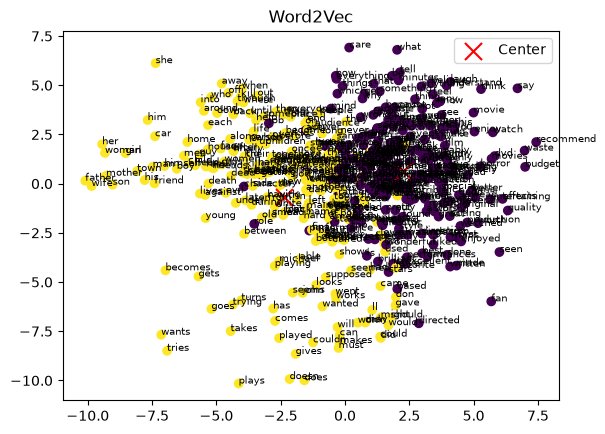

In [23]:
plt.figure()
plt.scatter(reduced_vectors[: , 0] , reduced_vectors[: , 1] , c=clusters , cmap="viridis")

centers = pca.transform(model_Kmeans.cluster_centers_)
plt.scatter(centers[:,0] , centers[: , 1] , c="red" , marker="x" , s=150 , label = "Center")
plt.legend()


for i , word in enumerate(words):
    plt.text(reduced_vectors[i , 0] , reduced_vectors[i , 1] , word , fontsize=7 )

plt.title("Word2Vec")
plt.show()